# SDS 336 Group Project: Midterm Checkpoint Hypotheses
**Dataset:** Austin Police Department crime reports, 2003 to Oct 2026 (2.68M incidents)

This notebook builds on `01_eda.ipynb`. Run that first, because it creates the cached `data/processed/crime.parquet` file used here.

Each section follows the same pattern: **what we noticed → analysis → hypothesis → how we'd test it next.**

| # | Hypothesis (short) | Method |
|---|---|---|
| H1 | Fast reporting, not just crime type, drives whether a case is solved | Logistic regression |
| H2 | A time recorded "on the hour" marks a crime that was discovered, not witnessed | Descriptive anomaly analysis + logistic regression |
| H3 | Falling clearance rates are not explained by a changing crime mix | Direct standardization (mix adjustment) |
| H4 | Family violence spikes on family holidays, even when other crime drops | Linear regression on daily counts (fixed effects) |
| H5 | Neighborhoods differ in the *kind* of crime, not only the amount | K-means clustering + PCA |

**Throughout:** "cleared" means clearance status C (arrest) or O (exception). We use **2009 and later** for anything involving clearance, because clearance coding before 2009 is inconsistent (see `01_eda`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = ROOT / "data" / "processed" / "crime.parquet"
FIG = ROOT / "figures"
assert CACHE.exists(), "Run notebooks/01_eda.ipynb first to build the parquet cache"

pd.set_option("display.width", 140)
SEED = 336

# Same plot style as 01_eda
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CATS = [BLUE, ORANGE, AQUA, YELLOW]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f3a582", "#b8461d"])
pct = mtick.PercentFormatter(1, decimals=0)
years_axis = lambda ax: ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))

def pretty(name):
    """Readable label for an offense or feature name."""
    out = name.title()
    for a, b in [("Dwi", "DWI"), ("Dating Vio", "Dating Violence"), ("10Pm-4Am", "10pm-4am"), ("Non Residence", "Non-Residence")]:
        out = out.replace(a, b)
    return out

def savefig(name):
    FIG.mkdir(exist_ok=True)
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

df = pd.read_parquet(CACHE)
df["on_hour"] = df["occurred_date_time"].dt.minute.eq(0)

# Analysis frame for clearance questions: 2009-2025, known status, sane report lag
clr = df[df["year"].between(2009, 2025) & df["clearance"].notna() & (df["report_lag_days"] >= 0)].copy()
clr["cleared"] = clr["clearance"].ne("Not cleared")
clr["offense"] = clr["highest_offense_description"].astype(str)
print(f"{len(df):,} incidents total; {len(clr):,} in the 2009-2025 clearance frame "
      f"({clr['cleared'].mean():.1%} cleared)")

2,676,798 incidents total; 1,619,851 in the 2009-2025 clearance frame (27.5% cleared)


---
## H1. Reporting speed drives clearance, beyond crime type

**What we noticed:** In `01_eda`, half of incidents are reported within about 15 minutes, but there is a long tail of reports days or months later. We wanted to know whether that delay matters for solving the case.

In [2]:
LAG_BINS = [0, 1/24, 1, 7, 30, np.inf]
LAG_LABELS = ["<1 h", "1 h-1 d", "1-7 d", "1-4 wk", ">4 wk"]
clr["lag_bucket"] = pd.cut(clr["report_lag_days"], LAG_BINS, labels=LAG_LABELS, right=False)

overall = clr.groupby("lag_bucket", observed=True)["cleared"].agg(rate="mean", n="size")
by_cat = clr.pivot_table(index="lag_bucket", columns="category_description", values="cleared",
                         aggfunc="mean", observed=True)
overall.assign(rate=lambda t: t["rate"].round(3))

,rate,n
lag_bucket,,
<1 h,0.411,864006
1 h-1 d,0.169,422665
1-7 d,0.050,183656
1-4 wk,0.047,90833
>4 wk,0.082,58691


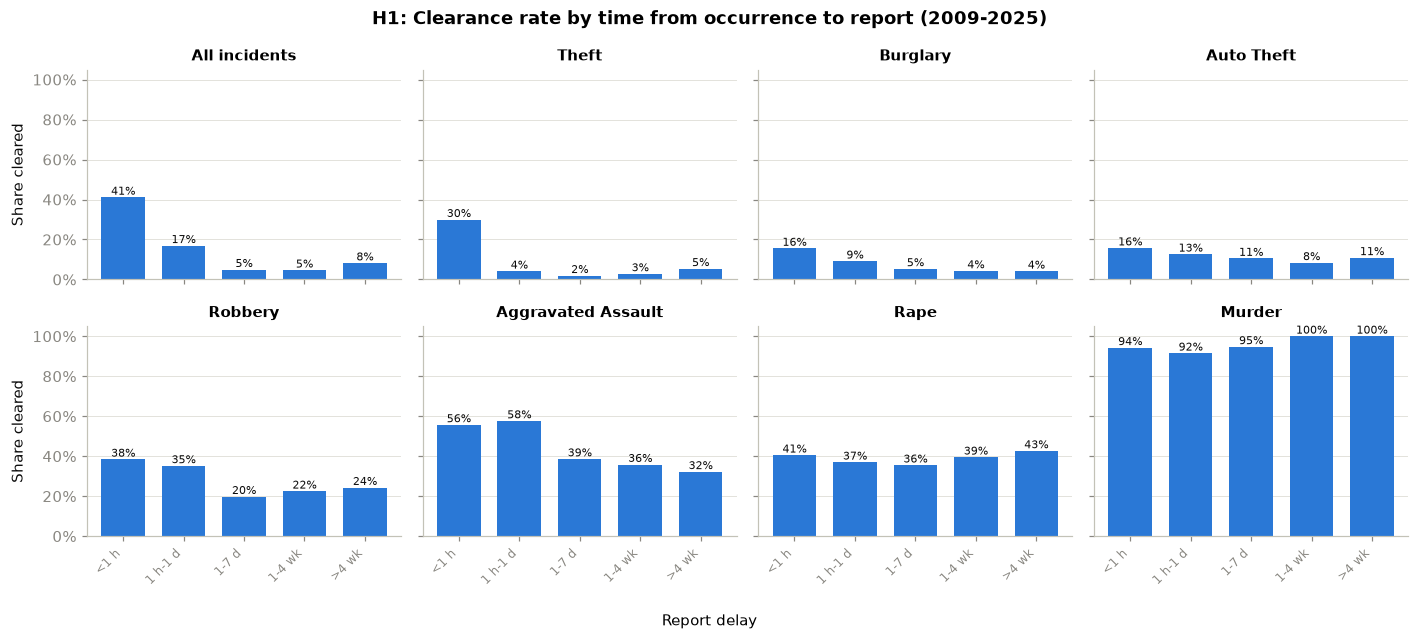

In [3]:
panels = ["All incidents", "Theft", "Burglary", "Auto Theft", "Robbery", "Aggravated Assault", "Rape", "Murder"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, panels):
    s = overall["rate"] if name == "All incidents" else by_cat[name]
    ax.bar(range(len(s)), s.values, color=BLUE, width=0.72)
    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(len(s))); ax.set_xticklabels(LAG_LABELS, rotation=45, ha="right", fontsize=8)
    ax.yaxis.set_major_formatter(pct); ax.grid(axis="x", visible=False)
    for x, v in enumerate(s.values):
        ax.text(x, v, f"{v:.0%}", ha="center", va="bottom", fontsize=7, color=INK)
axes[0, 0].set_ylabel("Share cleared"); axes[1, 0].set_ylabel("Share cleared")
fig.suptitle("H1: Clearance rate by time from occurrence to report (2009-2025)", fontweight="bold")
fig.supxlabel("Report delay", fontsize=10)
fig.tight_layout(); savefig("h1_clearance_by_lag"); plt.show()

The raw pattern could just reflect crime mix: assaults are reported fast and cleared often, while thefts are reported late and rarely cleared. To check this, we fit a **logistic regression** that holds the specific offense fixed (the top 40 offense descriptions, with the rest grouped as "other") and compare models with and without report delay.

In [4]:
TOP_OFF = clr["offense"].value_counts().head(40).index

def design(frame, extra=()):
    """Offense dummies + context features (+ optional extra columns)."""
    X = pd.get_dummies(frame["offense"].where(frame["offense"].isin(TOP_OFF), "OTHER"),
                       prefix="off", dtype=float)
    X["family_violence"] = frame["family_violence"].astype(float)
    X["weekend"] = frame["dow"].ge(5).astype(float).values
    X["night"] = (frame["hour"].ge(22) | frame["hour"].lt(4)).astype(float).values
    for c in extra:
        X[c] = frame[c].astype(float).values
    return X

sample = clr.sample(400_000, random_state=SEED)
sample["log10_lag_hours"] = np.log10(1 + sample["report_lag_days"] * 24)
train, test = train_test_split(sample, test_size=0.25, random_state=SEED, stratify=sample["cleared"])

def fit_auc(extra):
    Xtr, Xte = design(train, extra), design(test, extra)
    m = LogisticRegression(C=1e4, max_iter=3000).fit(Xtr, train["cleared"])
    return m, Xtr.columns, roc_auc_score(test["cleared"], m.predict_proba(Xte)[:, 1])

m0, _, auc0 = fit_auc(())
m1, cols1, auc1 = fit_auc(("log10_lag_hours",))
or_lag = np.exp(m1.coef_[0][list(cols1).index("log10_lag_hours")])
print(f"Held-out AUC, offense + context only:      {auc0:.3f}")
print(f"Held-out AUC, + log10(report delay hours): {auc1:.3f}")
print(f"Odds ratio per 10x longer delay (offense held fixed): {or_lag:.2f}")

Held-out AUC, offense + context only:      0.879
Held-out AUC, + log10(report delay hours): 0.896
Odds ratio per 10x longer delay (offense held fixed): 0.42


**Result.** Incidents reported within an hour are cleared **41%** of the time. That falls to 17% for reports within a day and about 5% after a day. The gap is largest for property crime: theft goes from 30% to 4%. The logistic regression holds the specific offense, the family-violence flag, weekend and night fixed. Even so, **each 10× longer delay cuts the odds of clearance by about 58% (odds ratio 0.42)**, and adding delay raises held-out AUC from 0.879 to 0.896.

**Exceptions:** clearance for murder (more than 90%) and rape (about 40%) barely depends on delay. These cases are investigated whenever they're reported.

> **H1:** For property and street crimes, the chance a case is cleared falls sharply with reporting delay, beyond what offense type explains. For the most serious violent crimes, delay does not matter.

**How we'd test it next:** a delay × crime-category interaction in a logistic model or tree ensemble. Then check whether delay works only as a stand-in for "a suspect was at the scene" (for example, by comparing within APD sector and within offense).

---
## H2. An "on the hour" time stamp marks a crime that was discovered, not witnessed

**What we noticed (an anomaly):** 26% of all incidents have an occurrence time of exactly `HH:00`. If times were recorded to the minute, that number would be about 1.7%. So these times are rounded estimates. We asked which crimes get rounded times.

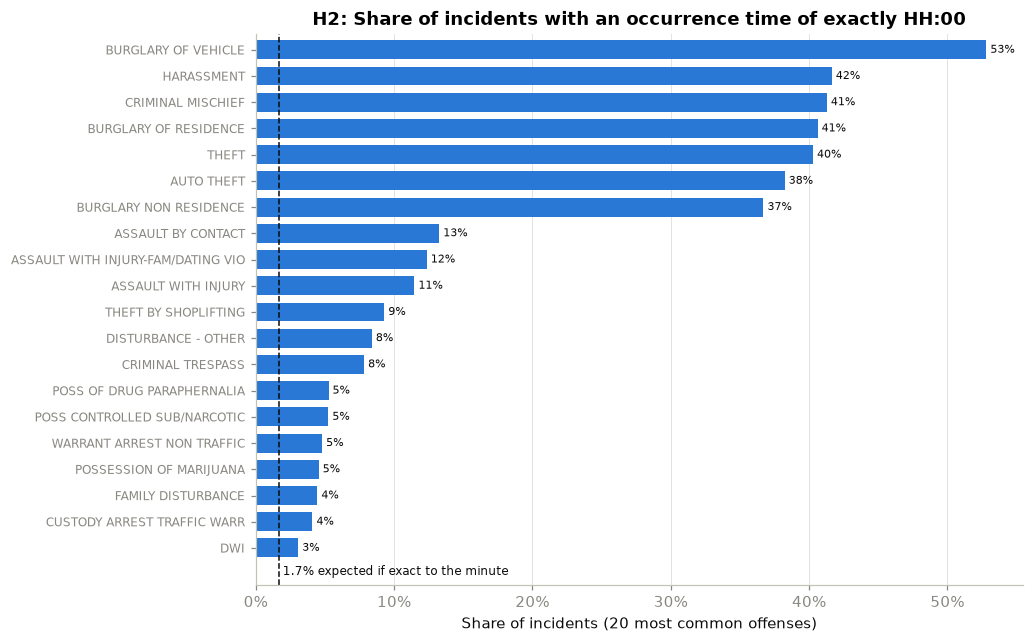

In [5]:
top_off = df["highest_offense_description"].value_counts().head(20).index
share = (df[df["highest_offense_description"].isin(top_off)]
           .groupby("highest_offense_description", observed=True)["on_hour"].mean()
           .sort_values())
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(share.index.astype(str), share.values, color=BLUE, height=0.72)
ax.axvline(1/60, color=INK, lw=1, ls="--")
ax.text(1/60, -0.9, " 1.7% expected if exact to the minute", fontsize=8, color=INK, va="center")
ax.set_ylim(-1.4, len(share) - 0.4)
ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set(title="H2: Share of incidents with an occurrence time of exactly HH:00",
       xlabel="Share of incidents (20 most common offenses)", ylabel="")
ax.tick_params(axis="y", labelsize=8)
for y, v in enumerate(share.values):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=7.5, color=INK)
savefig("h2_on_hour_by_offense"); plt.show()

Crimes where an officer or victim is present when it happens (DWI, drug possession, warrant arrests, family disturbances) almost never have rounded times. Crimes found later (vehicle burglary, identity theft, residential burglary, criminal mischief) have rounded times 40-60% of the time.

So a rounded time looks like a **proxy for "nobody saw it happen."** If that's right, rounded-time incidents should be cleared less often **even within the same offense.**

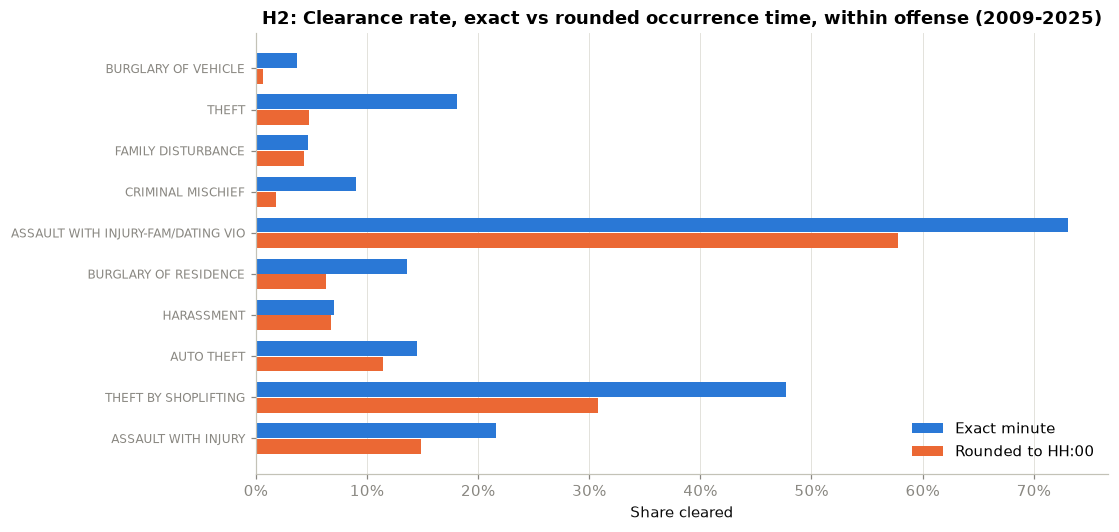

Rounded time is associated with lower clearance in 10 of 10 offenses


In [6]:
cmp_ = (clr.groupby(["offense", "on_hour"])["cleared"].agg(rate="mean", n="size")
           .unstack("on_hour"))
cmp_ = cmp_[(cmp_[("n", False)] >= 3000) & (cmp_[("n", True)] >= 3000)]
cmp_ = cmp_.assign(total=cmp_[("n", False)] + cmp_[("n", True)]).sort_values("total", ascending=False).head(10)
exact, rounded = cmp_[("rate", False)], cmp_[("rate", True)]

fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(cmp_))[::-1]
ax.barh(y + 0.19, exact.values, height=0.36, color=BLUE, label="Exact minute")
ax.barh(y - 0.19, rounded.values, height=0.36, color=ORANGE, label="Rounded to HH:00")
ax.set_yticks(y); ax.set_yticklabels(cmp_.index, fontsize=8)
ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.set(title="H2: Clearance rate, exact vs rounded occurrence time, within offense (2009-2025)",
       xlabel="Share cleared", ylabel="")
savefig("h2_clearance_exact_vs_rounded"); plt.show()

print(f"Rounded time is associated with lower clearance in {(rounded < exact).sum()} of {len(cmp_)} offenses")

In [7]:
# Same logistic model as H1, adding the on-hour flag: does it add information beyond offense AND delay?
m2, cols2, auc2 = fit_auc(("log10_lag_hours", "on_hour"))
or_hour = np.exp(m2.coef_[0][list(cols2).index("on_hour")])
lag_med = clr.groupby("on_hour")["report_lag_days"].median() * 24
print(f"Median report delay: exact time {lag_med[False]:.1f} h vs rounded time {lag_med[True]:.1f} h")
print(f"Odds ratio for rounded time (offense + delay held fixed): {or_hour:.2f}")
print(f"Held-out AUC: {auc1:.3f} -> {auc2:.3f} after adding on_hour")

Median report delay: exact time 0.0 h vs rounded time 20.5 h
Odds ratio for rounded time (offense + delay held fixed): 0.61
Held-out AUC: 0.896 -> 0.898 after adding on_hour


**Result.** In **all 10** high-volume offenses, incidents with a rounded time are cleared less often than those with an exact time. Examples: theft 18% vs 5%, shoplifting 48% vs 31%, family-violence assault 73% vs 58%. Rounded-time incidents are also reported much later (median 20.5 hours vs 0 hours). Holding both offense **and** report delay fixed, a rounded time still has an **odds ratio of 0.61** for clearance. The AUC gain is small (0.896 → 0.898) because much of the signal overlaps with delay.

> **H2:** An occurrence time rounded to the hour is a recorded sign that nobody saw the crime happen; it was discovered later. These incidents are less likely to be cleared, even compared with the same offense and the same reporting delay.

**How we'd test it next:** use `on_hour` as a feature in the clearance model. Check whether other placeholder values carry the same signal, such as the 1st-of-month dates found in H4. If the data has narrative fields, check whether the flag matches a "discovered later" description.

---
## H3. Falling clearance rates are not explained by a changing crime mix

**What we noticed:** The overall clearance rate fell from about 34% (2009) to 17% (2020-21). Over the same period the *mix* of crimes changed. For example, shoplifting and DWI, which are almost always cleared, became a smaller share of incidents. Is the decline just that mix shift?

**Method (direct standardization):** For each year, take that year's clearance rate *for each offense* and weight it by the **fixed 2009-2012 offense mix**. If the adjusted line stays flat, the decline is all mix. If it falls, police are clearing fewer cases of the same kind.

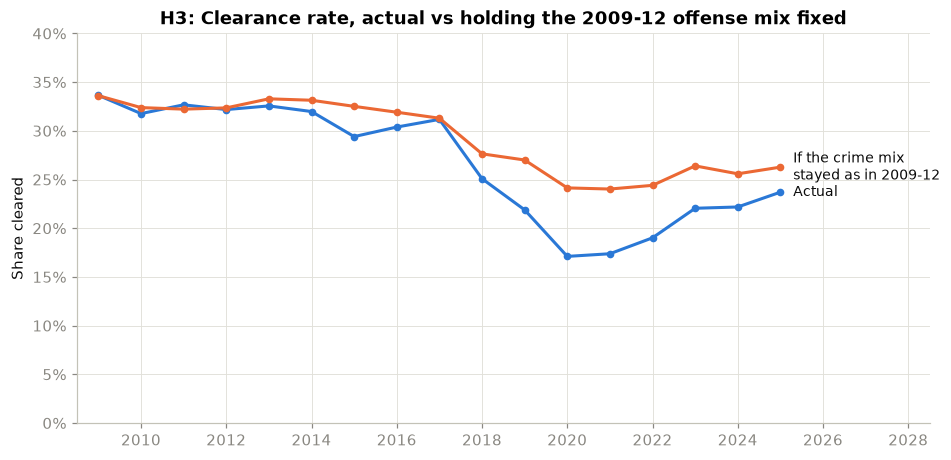

year           2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
raw           0.336  0.318  0.327  0.322  0.326  0.320  0.294  0.304  0.312  0.251  0.219  0.171  0.174  0.190  0.220  0.222  0.237
mix_adjusted  0.336  0.324  0.322  0.324  0.333  0.331  0.325  0.319  0.313  0.276  0.270  0.241  0.240  0.244  0.264  0.256  0.263

2009 -> 2021 drop: actual 33.6% -> 17.4%; mix-held-fixed 33.6% -> 24.0%
Share of the decline that happens WITHIN offenses: 59%


In [8]:
clr_y = clr[clr["year"].between(2009, 2025)]
base_mix = clr_y.loc[clr_y["year"] <= 2012, "offense"].value_counts(normalize=True)
rate_yo = clr_y.groupby(["year", "offense"])["cleared"].mean().unstack()
common = base_mix.index.intersection(rate_yo.columns)
filled = rate_yo[common].fillna(rate_yo[common].mean())   # rare offense-years: use the offense's average
adjusted = (filled * base_mix[common]).sum(axis=1) / base_mix[common].sum()
raw = clr_y.groupby("year")["cleared"].mean()
trend = pd.DataFrame({"raw": raw, "mix_adjusted": adjusted})

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(trend.index, trend["raw"], color=BLUE, lw=2, marker="o", ms=4)
ax.plot(trend.index, trend["mix_adjusted"], color=ORANGE, lw=2, marker="o", ms=4)
ax.text(2025.3, trend["raw"].iloc[-1], "Actual", color=INK, va="center", fontsize=9)
ax.text(2025.3, trend["mix_adjusted"].iloc[-1], "If the crime mix\nstayed as in 2009-12", color=INK, va="center", fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.4); ax.set_xlim(2008.5, 2028.5)
ax.set(title="H3: Clearance rate, actual vs holding the 2009-12 offense mix fixed", xlabel="", ylabel="Share cleared")
years_axis(ax)
savefig("h3_mix_adjusted_clearance"); plt.show()

r0, r1 = trend.loc[2009], trend.loc[2021]
within = (r0["mix_adjusted"] - r1["mix_adjusted"]) / (r0["raw"] - r1["raw"])
print(trend.round(3).T.to_string())
print(f"\n2009 -> 2021 drop: actual {r0['raw']:.1%} -> {r1['raw']:.1%}; "
      f"mix-held-fixed {r0['mix_adjusted']:.1%} -> {r1['mix_adjusted']:.1%}")
print(f"Share of the decline that happens WITHIN offenses: {within:.0%}")

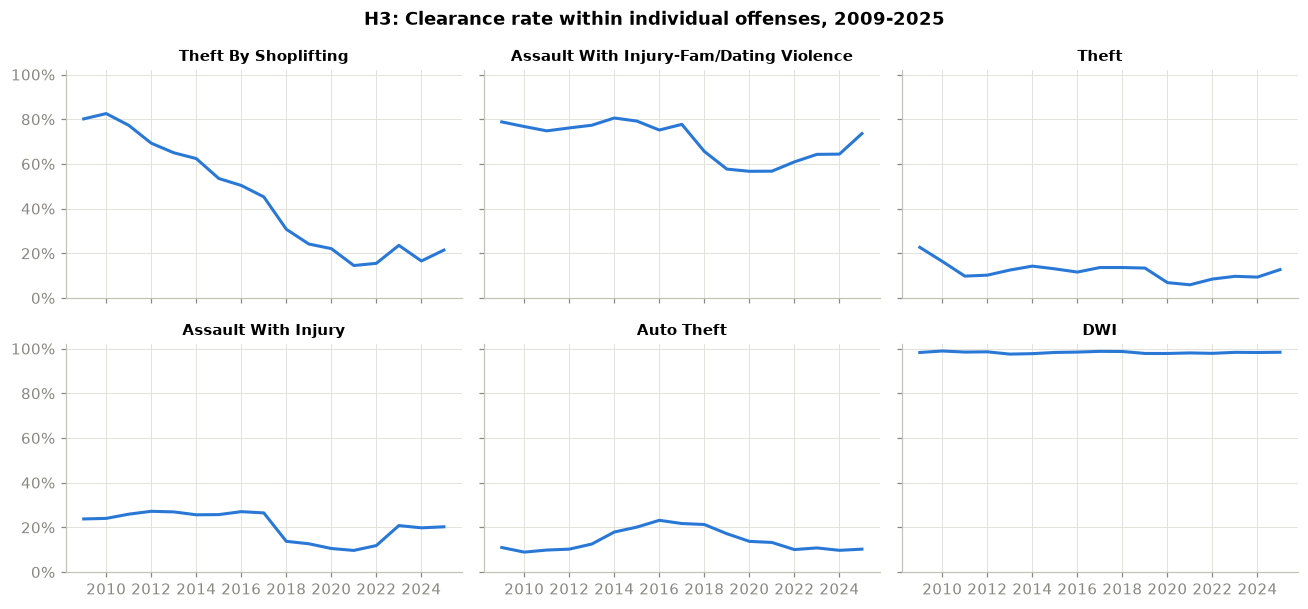

In [9]:
show = ["THEFT BY SHOPLIFTING", "ASSAULT WITH INJURY-FAM/DATING VIO", "THEFT",
        "ASSAULT WITH INJURY", "AUTO THEFT", "DWI"]
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True, sharey=True)
for ax, o in zip(axes.flat, show):
    ax.plot(rate_yo.index, rate_yo[o], color=BLUE, lw=2)
    ax.set_title(pretty(o), fontsize=9.5); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1.02)
    years_axis(ax)
fig.suptitle("H3: Clearance rate within individual offenses, 2009-2025", fontweight="bold")
fig.tight_layout(); savefig("h3_within_offense"); plt.show()

**Result.** Clearance held steady at about 31-34% through 2017. It then fell to 17% by 2020-21 and partly recovered to 24% by 2025. **Holding the 2009-12 crime mix fixed, the rate still falls from 33.6% to 24.0%.** So **about 59% of the 2009-2021 decline happens within offenses**, and only about 41% comes from the changing mix. The decline within offenses is large for shoplifting (80% → about 20%) and for assault with injury (24% → 10%). Family-violence assault fell from 79% to 57% and has since recovered to 74%. DWI stays flat at about 98%, as expected since a DWI report almost always involves an arrest. It works as a built-in comparison case.

> **H3:** Austin's post-2017 drop in clearance is mostly because the *same kinds* of cases are cleared less often, not because different crimes are being reported. The sharp break in 2018 and the low point in 2020-21 suggest an institutional change (staffing, policy or how incidents are reported) rather than a gradual shift in crime.

**How we'd test it next:** a segmented (piecewise) regression to test for a break in 2018; break the decline down by APD sector; and compare the timing with public records on APD staffing and reporting-policy changes. We are not claiming a cause yet.

---
## H4. Family violence spikes on family holidays, even when other crime drops

**What we noticed:** We first checked whether family violence rose during the 2020 COVID lockdown. After accounting for the existing trend and seasonality, it didn't (see the summary at the end). Looking at daily counts instead, a stronger pattern appeared: **on Christmas Day, total incidents fall but family-violence incidents rise.**

**A second anomaly to control for:** the **1st of every month** has about 25% more incidents than nearby days, for both family-violence and other incidents. This is probably a recording artifact (an unknown date gets set to the 1st), so the model controls for it.

**Method (linear regression on log daily counts, 2009-2025):** For family-violence and non-family-violence incidents separately, we model the log of the daily count with year, month and day-of-week fixed effects, a 1st-of-month dummy and holiday dummies. `exp(coefficient) - 1` is the % change on that holiday compared with a normal day of the same weekday, month and year.

In [10]:
import statsmodels.api as sm

d = df[df["year"].between(2009, 2025)]
daily = (d.assign(date=d["occurred_date_time"].dt.normalize())
           .groupby(["date", "family_violence"]).size().unstack()
           .rename(columns={True: "fv", False: "non_fv"}))
idx = daily.index

def nth_weekday(year, month, weekday, n):
    days = pd.date_range(f"{year}-{month:02d}-01", periods=31, freq="D")
    return days[(days.month == month) & (days.dayofweek == weekday)][n]

HOLIDAYS = {
    "New Year's Day": lambda y: pd.Timestamp(f"{y}-01-01"),
    "Memorial Day":   lambda y: nth_weekday(y, 5, 0, -1),
    "July 4":         lambda y: pd.Timestamp(f"{y}-07-04"),
    "Labor Day":      lambda y: nth_weekday(y, 9, 0, 0),
    "Thanksgiving":   lambda y: nth_weekday(y, 11, 3, 3),
    "Christmas Eve":  lambda y: pd.Timestamp(f"{y}-12-24"),
    "Christmas Day":  lambda y: pd.Timestamp(f"{y}-12-25"),
    "New Year's Eve": lambda y: pd.Timestamp(f"{y}-12-31"),
}
years = range(2009, 2026)
Xd = pd.concat([pd.get_dummies(idx.year, prefix="y", drop_first=True, dtype=float),
                pd.get_dummies(idx.month, prefix="m", drop_first=True, dtype=float),
                pd.get_dummies(idx.dayofweek, prefix="dow", drop_first=True, dtype=float)], axis=1)
Xd.index = idx
Xd["1st of month"] = (idx.day == 1).astype(float)
for name, f in HOLIDAYS.items():
    Xd[name] = idx.isin([f(y) for y in years]).astype(float)
Xd = sm.add_constant(Xd)

effects = {}
for col in ["fv", "non_fv"]:
    ols = sm.OLS(np.log(daily[col]), Xd).fit(cov_type="HC1")
    ci = ols.conf_int()
    terms = ["1st of month"] + list(HOLIDAYS)
    effects[col] = pd.DataFrame({"effect": np.exp(ols.params[terms]) - 1,
                                 "lo": np.exp(ci.loc[terms, 0]) - 1,
                                 "hi": np.exp(ci.loc[terms, 1]) - 1})
    print(f"{col:>6}: R^2 = {ols.rsquared:.2f}, mean {daily[col].mean():.0f} incidents/day")

table = pd.concat(effects, axis=1)
table.map(lambda v: f"{v:+.0%}") if hasattr(table, "map") else table.applymap(lambda v: f"{v:+.0%}")

    fv: R^2 = 0.30, mean 20 incidents/day
non_fv: R^2 = 0.80, mean 275 incidents/day


fv              non_fv            
               effect    lo     hi effect    lo    hi
1st of month     +24%  +20%   +28%   +23%  +21%  +24%
New Year's Day   +91%  +69%  +115%   +26%  +20%  +33%
Memorial Day     +28%  +19%   +39%    -1%   -5%   +2%
July 4           +31%  +21%   +42%    -1%   -4%   +3%
Labor Day        +23%  +13%   +34%    +0%   -4%   +4%
Thanksgiving     +19%   +7%   +33%   -23%  -26%  -20%
Christmas Eve     +9%   -2%   +21%   -13%  -19%   -7%
Christmas Day    +38%  +19%   +59%   -29%  -33%  -25%
New Year's Eve   +15%   +4%   +28%    -3%   -7%   +1%

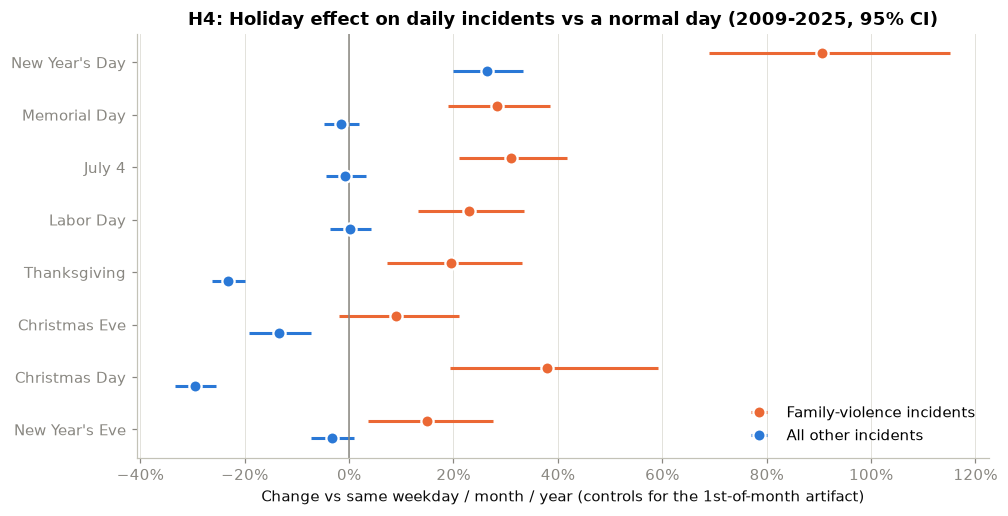

In [11]:
order = list(HOLIDAYS)[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(order))
for off, col, color, label in [(0.17, "fv", ORANGE, "Family-violence incidents"),
                               (-0.17, "non_fv", BLUE, "All other incidents")]:
    e = effects[col].loc[order]
    ax.errorbar(e["effect"], y + off, xerr=[e["effect"] - e["lo"], e["hi"] - e["effect"]],
                fmt="o", ms=8, color=color, ecolor=color, elinewidth=2, capsize=0, label=label,
                markeredgecolor="white", markeredgewidth=1.5)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(y); ax.set_yticklabels(order)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set(title="H4: Holiday effect on daily incidents vs a normal day (2009-2025, 95% CI)",
       xlabel="Change vs same weekday / month / year (controls for the 1st-of-month artifact)")
savefig("h4_holiday_effects"); plt.show()

**Result.** On **every holiday we tested**, family violence goes up, while other incidents stay flat or fall:
- **Christmas Day:** family violence **+38%** (95% CI +19% to +59%), other incidents **−29%**
- **Thanksgiving:** +19% vs −23%
- **Memorial Day, July 4 and Labor Day:** family violence +23% to +31%, other incidents about 0%
- **New Year's Day:** family violence +91% on top of the 1st-of-month artifact, probably incidents from New Year's Eve that continue past midnight

Christmas Eve is the only holiday whose interval includes zero.

> **H4:** Family violence rises on holidays when families spend the day together at home, even on days when other crime drops. Family-violence risk seems to follow time spent together, not the overall level of activity in the city.

**Caveats and next steps:** holiday drinking could be a confounder. Comparing drinking-heavy holidays (July 4, New Year's Eve) with family-gathering holidays (Thanksgiving, Christmas), and looking at the hour of day on holidays, would help separate the two. A Poisson or negative-binomial model would suit count data better than OLS on log counts.

---
## H5. Neighborhoods differ in the *kind* of crime, not just the amount

**What we noticed:** Council districts differ a lot in raw incident counts. Counts mostly reflect population and activity, though. We wanted to know whether places also differ in **what kind** of crime happens there.

**Method:** For each census block group with at least 200 incidents in 2019-2025, we build a profile from its share of each of the 15 most common offenses (the rest grouped as "other"), plus the share at night, on weekends and flagged as family violence. We standardize the features, run **k-means**, and look at the result with **PCA**.

In [12]:
recent = df[df["year"].between(2019, 2025) & df["census_block_group"].notna()].copy()
off_r = recent["highest_offense_description"].astype(str)
top15 = off_r.value_counts().head(15).index
recent["offense_grp"] = np.where(off_r.isin(top15), off_r, "OTHER")

prof = pd.crosstab(recent["census_block_group"], recent["offense_grp"], normalize="index")
g = recent.groupby("census_block_group")
prof["NIGHT (10pm-4am)"] = g["hour"].apply(lambda h: (h.ge(22) | h.lt(4)).mean())
prof["WEEKEND"] = g["dow"].apply(lambda s: s.ge(5).mean())
prof["FAMILY VIOLENCE"] = g["family_violence"].mean()
counts = g.size()
prof = prof[counts.reindex(prof.index) >= 200]
Z = StandardScaler().fit_transform(prof)
print(f"{len(prof)} block groups x {prof.shape[1]} features")

ks = range(2, 9)
fits = {k: KMeans(k, n_init=20, random_state=SEED).fit(Z) for k in ks}
sil = pd.Series({k: silhouette_score(Z, fits[k].labels_) for k in ks}, name="silhouette")
inertia = pd.Series({k: fits[k].inertia_ for k in ks}, name="inertia")
pd.concat([inertia.round(0), sil.round(3)], axis=1).T

570 block groups x 19 features


,2,3,4,5,6,7,8
inertia,9174.00,8286.000,7546.000,7032.000,6608.000,6299.000,6026.000
silhouette,0.15,0.148,0.144,0.156,0.151,0.143,0.138


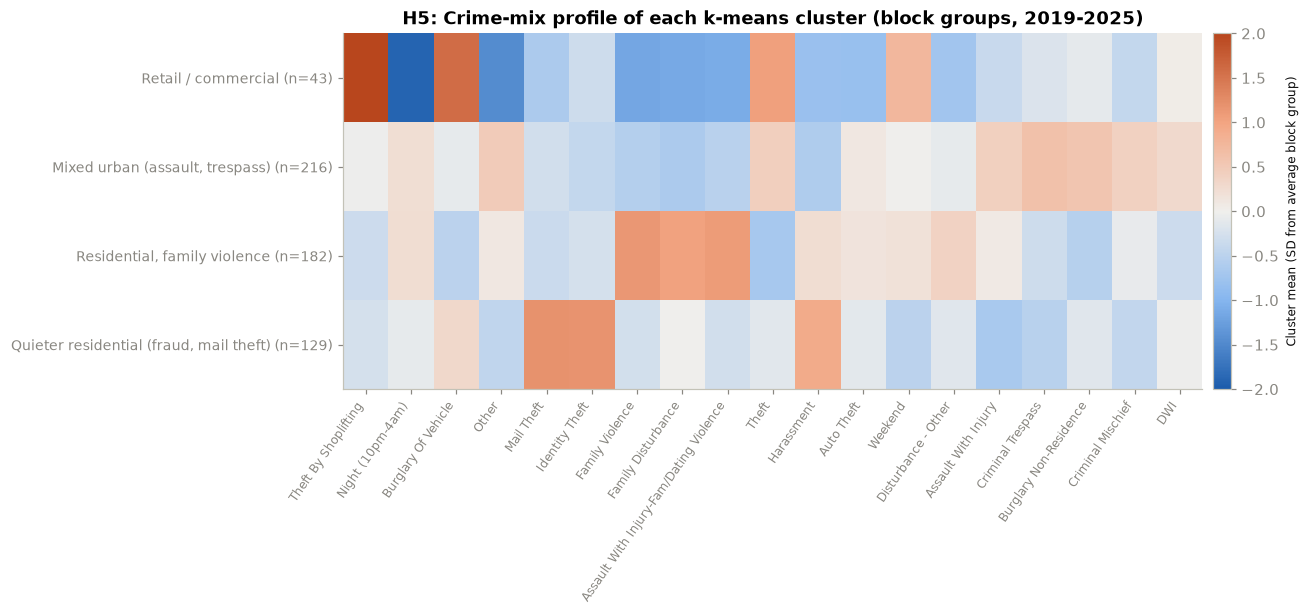

In [13]:
K = 4
labels = fits[K].labels_
cent = prof.groupby(labels).mean()

# Name clusters from their defining features (robust to k-means label order)
names, left = {}, set(cent.index)
for feat, name in [("THEFT BY SHOPLIFTING", "Retail / commercial"),
                   ("FAMILY VIOLENCE", "Residential, family violence"),
                   ("IDENTITY THEFT", "Quieter residential (fraud, mail theft)")]:
    c = cent.loc[sorted(left), feat].idxmax(); names[c] = name; left.discard(c)
names[left.pop()] = "Mixed urban (assault, trespass)"
prof["cluster"] = pd.Series(labels, index=prof.index).map(names)
ORDER = ["Retail / commercial", "Mixed urban (assault, trespass)", "Residential, family violence",
         "Quieter residential (fraud, mail theft)"]

zc = pd.DataFrame(Z, index=prof.index, columns=prof.columns[:-1]).groupby(prof["cluster"]).mean().loc[ORDER]
feat_order = zc.abs().max().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(zc[feat_order], cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(feat_order))); ax.set_xticklabels([pretty(f) for f in feat_order], rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels([f"{c} (n={(prof['cluster'] == c).sum()})" for c in ORDER], fontsize=9)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Cluster mean (SD from average block group)", fontsize=8)
ax.set_title("H5: Crime-mix profile of each k-means cluster (block groups, 2019-2025)")
savefig("h5_cluster_profiles"); plt.show()

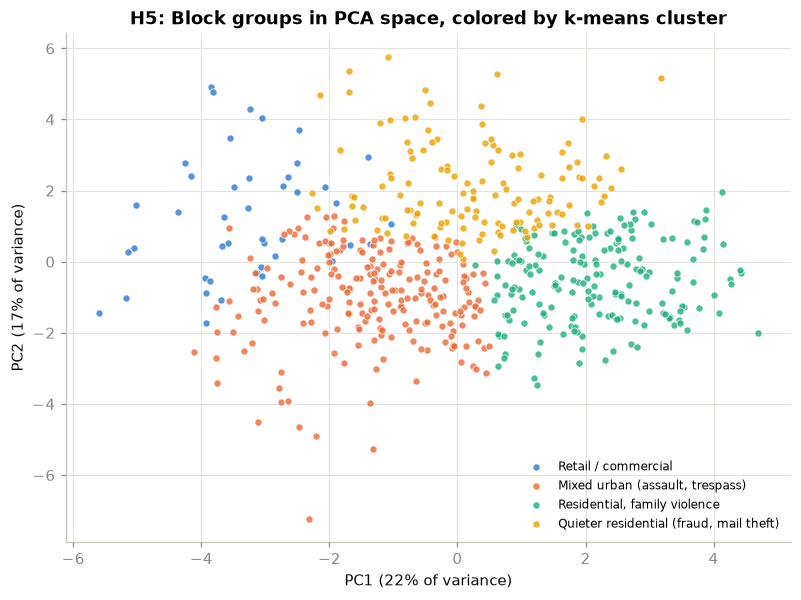

PC1 most negative: Theft, Theft By Shoplifting, Burglary Non-Residence, Burglary Of Vehicle
PC1 most positive: Harassment, Assault With Injury-Fam/Dating Violence, Family Disturbance, Family Violence


In [14]:
pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(8.5, 6))
for c, col in zip(ORDER, CATS):
    m = (prof["cluster"] == c).values
    ax.scatter(P[m, 0], P[m, 1], s=22, color=col, alpha=0.8, edgecolor="white", linewidth=0.6, label=c)
ev = pca.explained_variance_ratio_
ax.set(title="H5: Block groups in PCA space, colored by k-means cluster",
       xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%} of variance)")
ax.legend(frameon=False, fontsize=8, loc="best")
savefig("h5_pca_clusters"); plt.show()

loadings = pd.Series(pca.components_[0], index=prof.columns[:-1]).sort_values()
print("PC1 most negative:", ", ".join(pretty(f) for f in loadings.head(4).index))
print("PC1 most positive:", ", ".join(pretty(f) for f in loadings.tail(4).index))

In [15]:
# Follow-up: does neighborhood type relate to clearance (2019-2025)?
bg_cluster = prof["cluster"]
rc = clr[clr["year"].between(2019, 2025) & clr["census_block_group"].isin(bg_cluster.index)].copy()
rc["cluster"] = rc["census_block_group"].map(bg_cluster)
summary = (rc.groupby("cluster")
             .agg(block_groups=("census_block_group", "nunique"), incidents=("cleared", "size"),
                  clearance_rate=("cleared", "mean"))
             .loc[ORDER])
summary["median incidents / block group"] = counts.reindex(prof.index).groupby(prof["cluster"]).median().loc[ORDER]
summary.round(3)

,block_groups,incidents,clearance_rate,median incidents / block group
cluster,,,,
Retail / commercial,43,60397,0.172,1383.0
"Mixed urban (assault, trespass)",216,279833,0.231,1007.0
"Residential, family violence",182,157754,0.201,856.0
"Quieter residential (fraud, mail theft)",129,56853,0.133,406.0


**Result.** The silhouette score is only **0.14-0.16 for every k from 2 to 8**, so the clusters overlap. Austin's block groups form a **continuum, not distinct types.** The first principal component (22% of variance) is easy to interpret, though. It runs from **commercial property crime** (shoplifting, theft, vehicle and non-residential burglary) to **domestic crime** (family disturbance, family-violence assault, harassment). The four k-means clusters divide that continuum into:
- **Retail / commercial** (43 block groups): shoplifting and vehicle burglary, daytime and weekends
- **Mixed urban** (216): assault, trespass and non-residential burglary
- **Residential, family violence** (182)
- **Quieter residential** (129): identity theft, mail theft and harassment, with low volume

Clearance rates differ between clusters: **13%** in quieter residential areas compared with **23%** in mixed urban areas.

> **H5:** Austin neighborhoods differ mainly along one commercial-property ↔ domestic axis. Where a neighborhood sits on that axis, meaning its type of crime and not just its volume, helps explain how many of its cases are cleared.

**How we'd test it next:** join Census TIGER block-group shapes to map the clusters; use ACS population for per-capita rates; and add the cluster or PC1 score as a feature in the clearance model to see whether it adds anything beyond offense type.

---
## Tested and not supported: a 2020 lockdown spike in family violence

We expected family violence to rise during the March-August 2020 lockdown. We fit monthly counts for 2015-2019 with a linear regression (`count ~ trend + month-of-year`) and compared 2020 with that prediction.

In [16]:
monthly = (df[df["year"].between(2015, 2021)]
             .assign(month_start=lambda t: t["occurred_date_time"].dt.to_period("M").dt.to_timestamp())
             .groupby(["month_start", "family_violence"]).size().unstack()
             .rename(columns={True: "fv", False: "non_fv"}))
Xm = pd.get_dummies(monthly.index.month, prefix="m", drop_first=True, dtype=float)
Xm.index = monthly.index
Xm["t"] = (monthly.index.year - 2015) * 12 + monthly.index.month
fit_mask = monthly.index < "2020-01-01"
win = (monthly.index >= "2020-03-01") & (monthly.index <= "2020-08-31")
for col in ["fv", "non_fv"]:
    lr = LinearRegression().fit(Xm[fit_mask], monthly.loc[fit_mask, col])
    pred = lr.predict(Xm)
    sd = (monthly.loc[fit_mask, col] - pred[fit_mask]).std()
    act, exp_ = monthly.loc[win, col].sum(), pred[win].sum()
    print(f"{col:>6}, Mar-Aug 2020: actual {act:,.0f} vs expected {exp_:,.0f} ({act / exp_ - 1:+.1%}); "
          f"6-month noise ~ ±{2 * sd * np.sqrt(6) / exp_:.0%} (2 SD)")

    fv, Mar-Aug 2020: actual 4,097 vs expected 4,007 (+2.2%); 6-month noise ~ ±5% (2 SD)
non_fv, Mar-Aug 2020: actual 44,689 vs expected 46,119 (-3.1%); 6-month noise ~ ±3% (2 SD)


**Result.** Family violence in March-August 2020 was only **+2.2%** above the 2015-19 trend-and-seasonality baseline, which is within the ±5% noise band. Other incidents were −3.1%. The family-violence *share* did rise in 2020, but mostly because family violence had already been trending up since 2015. **We do not carry this hypothesis forward.** It led us to the holiday pattern in H4.

---
## Summary

| # | Hypothesis | Key evidence | Strength |
|---|---|---|---|
| H1 | Reporting delay lowers clearance beyond crime type | Odds ratio 0.42 per 10× delay; AUC 0.879 → 0.896 | Strong |
| H2 | A rounded "HH:00" time marks an unwitnessed crime, which is cleared less often | Lower clearance in 10/10 offenses; odds ratio 0.61 after controlling for offense and delay | Strong |
| H3 | The clearance decline is mostly within offenses, not a change in mix | 59% of the 2009→2021 drop remains after holding the mix fixed | Strong |
| H4 | Family violence rises on family holidays while other crime falls | Christmas +38% vs −29%; all 8 holidays positive | Strong |
| H5 | Neighborhoods vary along a commercial ↔ domestic crime axis that relates to clearance | PC1 = 22% of variance; cluster clearance 13-23%; silhouette only 0.15 | Moderate |
| (rejected) | A family-violence spike during the 2020 lockdown | +2.2%, within noise | Not supported |

**Where this points for the final project:** H1, H2 and H5 all give features for one model: **predict whether an incident will be cleared** from offense, reporting delay, time precision and neighborhood profile, using 2009+ data. H3 warns that the relationship shifts over time, so validate on later years (train on 2009-2019, test on 2022-2025). Don't use a random split.